# Multi-Channel Phase Bin Analysis Demo

Three analysis blocks:
1. **Single file** – time-domain waveform, PSD, and space-time plot for a specified channel
2. **Single file** – PSD probability-density map for a channel range
3. **Batch files** – PSD probability-density map averaged across multiple files

In [78]:
from pathlib import Path
import importlib

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
from scipy import signal

import phase_bin_tools as pbt
pbt = importlib.reload(pbt)

plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.family'] = 'DejaVu Sans'

---
## Block 1 – Time-domain waveform, PSD, and space-time plot

Read one `.bin` file and visualise a single channel.

In [84]:
# ── parameters ───────────────────────────────────────────────────────────────
B1_FILE       = Path(r"H:\WFBG7825_DATA2\0000002-fs-eDAS-10000Hz-0292pt-20260526T231829.671.bin")   # <-- change this
B1_FS         = 10000.0        # sampling rate (Hz)
B1_N_CHANNELS = 292            # number of channels  (points_per_frame)
B1_CHANNEL    = 150            # channel index to plot (0-based)

# space-time colour limits (set None for auto)
B1_VMIN = -0.5
B1_VMAX =  0.5
# ─────────────────────────────────────────────────────────────────────────────
print(f"File : {B1_FILE}")
print(f"fs   : {B1_FS} Hz  |  channels : {B1_N_CHANNELS}  |  target channel : {B1_CHANNEL}")

File : H:\WFBG7825_DATA2\0000002-fs-eDAS-10000Hz-0292pt-20260526T231829.671.bin
fs   : 10000.0 Hz  |  channels : 292  |  target channel : 150


In [85]:
# Read data – shape (n_frames, n_channels) in radians
data_b1 = pbt.read_single_channel_phase_bin(
    B1_FILE, points_per_frame=B1_N_CHANNELS
)
print(f"data shape : {data_b1.shape}   min/max (rad) : {data_b1.min():.4f} / {data_b1.max():.4f}")

data shape : (50000, 292)   min/max (rad) : -1.8218 / 2.0724


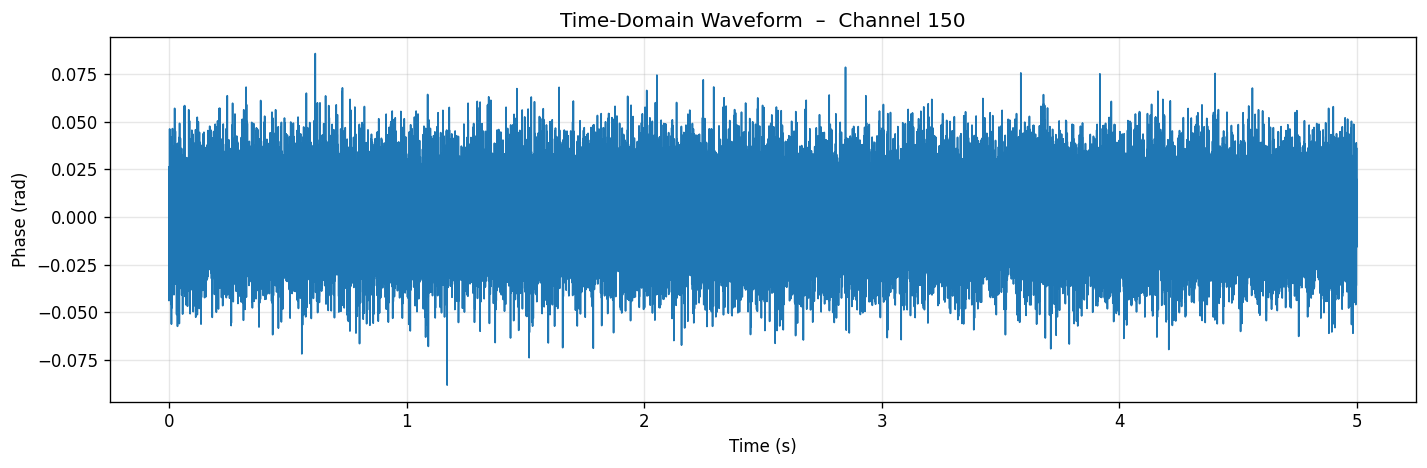

In [86]:
# ── Time-domain waveform ──────────────────────────────────────────────────────
waveform = pbt.extract_point_waveform(data_b1, B1_CHANNEL)

fig, ax = plt.subplots(figsize=(12, 4))
pbt.plot_point_waveform(
    waveform,
    sample_rate_hz=B1_FS,
    title=f"Time-Domain Waveform  –  Channel {B1_CHANNEL}",
    ax=ax,
)
plt.tight_layout()
plt.show()

In [88]:
# ── PSD (Welch) ───────────────────────────────────────────────────────────────
freq_hz, psd_db = pbt.compute_point_psd(waveform, sample_rate_hz=B1_FS)
%matplotlib qt
fig, ax = plt.subplots(figsize=(12, 4))
pbt.plot_point_psd(
    freq_hz, psd_db,
    title=f"PSD  –  Channel {B1_CHANNEL}",
    ax=ax,
)
ax.set_ylabel("PSD (dB re 1 rad²/Hz)")
ax.set_xlim([0, B1_FS / 2])
plt.tight_layout()
plt.show()

In [89]:
# ── Space-time plot (all channels) ────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 6))
pbt.plot_space_time(
    data_b1,
    sample_rate_hz=B1_FS,
    cmap="jet",
    title="Space-Time Plot",
    colorbar_label="Phase (rad)",
    vmin=B1_VMIN,
    vmax=B1_VMAX,
    ax=ax,
)
plt.tight_layout()
plt.show()

---
## Block 2 – PSD probability-density map (single file, channel range)

For every frequency bin, build a histogram of PSD values across the selected
channels, then display the result as a 2-D colour image.
A mean-PSD curve is overlaid.

In [91]:
# # ── parameters ───────────────────────────────────────────────────────────────
# B2_FILE       = Path(r"F:\7821+bigeguanglu\0000002-eDAS-4000Hz-0426pt-20260411T235259.142.bin")   # <-- change this
# B2_FS         = 4000.0
# B2_N_CHANNELS = 426
# B2_CH_START   = 1      # first channel index (0-based, inclusive)
# B2_CH_END     = 426      # last  channel index (0-based, exclusive)

# # Welch settings
# B2_NFFT    = 2**12       # FFT length
# B2_OVERLAP = 0.5         # fractional overlap

# # PSD density histogram
# B2_NBINS = 150

# # Plot display range
# B2_FREQ_XLIM = [1, B2_FS / 2]
# B2_PSD_YLIM  = None      # e.g. [-100, -40]; set None for auto
# # ─────────────────────────────────────────────────────────────────────────────
# print(f"Channel range : [{B2_CH_START}, {B2_CH_END})  →  {B2_CH_END - B2_CH_START} channels")

# ── parameters ───────────────────────────────────────────────────────────────
B2_FILE       = Path(r"H:\WFBG7825_DATA2\0000002-fs-eDAS-10000Hz-0292pt-20260526T231829.671.bin")   # <-- change this
B2_FS         = 10000.0
B2_N_CHANNELS = 292
B2_CH_START   = 3      # first channel index (0-based, inclusive)
B2_CH_END     = 292     # last  channel index (0-based, exclusive)

# Welch settings
B2_NFFT    = 2**12       # FFT length
B2_OVERLAP = 0.5         # fractional overlap

# PSD density histogram
B2_NBINS = 150

# Plot display range
B2_FREQ_XLIM = [1, B2_FS / 2]
B2_PSD_YLIM  = None      # e.g. [-100, -40]; set None for auto
# ─────────────────────────────────────────────────────────────────────────────
print(f"Channel range : [{B2_CH_START}, {B2_CH_END})  →  {B2_CH_END - B2_CH_START} channels")

Channel range : [3, 292)  →  289 channels


In [92]:
data_b2 = pbt.read_single_channel_phase_bin(
    B2_FILE, points_per_frame=B2_N_CHANNELS
)
# Select channel slice → shape (n_frames, n_selected)
data_sel = data_b2[:, B2_CH_START:B2_CH_END]
n_ch = data_sel.shape[1]
print(f"Selected data shape : {data_sel.shape}")

Selected data shape : (50000, 289)


In [93]:
def compute_psd_all_channels(
    data: np.ndarray,
    fs: float,
    nfft: int,
    overlap: float,
) -> tuple[np.ndarray, np.ndarray]:
    """Compute Welch PSD for every column; return (freq_hz, psd_dB [nFreq x nCh])."""
    window   = np.hamming(nfft)
    noverlap = int(nfft * overlap)
    n_ch = data.shape[1]

    # compute for first channel to get frequency axis
    f, p0 = signal.welch(
        data[:, 0], fs=fs,
        window=window, nperseg=nfft, noverlap=noverlap,
        nfft=nfft, scaling="density", return_onesided=True,
    )
    psd_dB = np.empty((len(f), n_ch), dtype=np.float64)
    psd_dB[:, 0] = 10.0 * np.log10(p0 + 1e-20)

    for i in range(1, n_ch):
        _, pi = signal.welch(
            data[:, i], fs=fs,
            window=window, nperseg=nfft, noverlap=noverlap,
            nfft=nfft, scaling="density", return_onesided=True,
        )
        psd_dB[:, i] = 10.0 * np.log10(pi + 1e-20)

    return f, psd_dB


freq_b2, psd_dB_b2 = compute_psd_all_channels(
    data_sel, B2_FS, B2_NFFT, B2_OVERLAP
)
print(f"PSD matrix shape : {psd_dB_b2.shape}  (nFreq x nChannels)")

PSD matrix shape : (2049, 289)  (nFreq x nChannels)


In [94]:
def build_psd_density_map(
    psd_dB: np.ndarray,
    n_bins: int = 150,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Build a (nFreq, nBins) probability-density map from a (nFreq, nCh) PSD matrix."""
    n_freq, n_ch = psd_dB.shape
    min_val = psd_dB.min() - 5.0
    max_val = psd_dB.max() + 5.0
    edges   = np.linspace(min_val, max_val, n_bins + 1)
    centers = 0.5 * (edges[:-1] + edges[1:])
    dbin    = edges[1] - edges[0]

    density = np.empty((n_freq, n_bins), dtype=np.float64)
    for i in range(n_freq):
        counts, _ = np.histogram(psd_dB[i, :], bins=edges)
        density[i, :] = counts / (n_ch * dbin)

    return density, centers, edges


density_b2, bin_centers_b2, _ = build_psd_density_map(psd_dB_b2, B2_NBINS)
print(f"Density map shape : {density_b2.shape}  (nFreq x nBins)")

Density map shape : (2049, 150)  (nFreq x nBins)


In [95]:
def make_white_fade_colormap(base_cmap_name: str = "viridis", n_white: int = 32, n_total: int = 256):
    """Return a colormap that fades from white (low values) to the base colormap."""
    base = plt.colormaps[base_cmap_name](np.linspace(0, 1, n_total))
    white = np.array([1.0, 1.0, 1.0, 1.0])
    for i in range(n_white):
        k = 3
        alpha = 1.0 - (i / n_white) ** k   # cubic fade
        base[i, :3] = (1 - alpha) * base[i, :3] + alpha * white[:3]
    return mcolors.ListedColormap(base)

In [101]:
def plot_psd_pdf(
    freq_hz: np.ndarray,
    bin_centers: np.ndarray,
    density: np.ndarray,
    psd_dB: np.ndarray,
    freq_xlim=None,
    psd_ylim=None,
    title: str = "PDF of PSD",
):
    """Render the PSD probability-density image with mean-PSD overlay."""
    cmap = make_white_fade_colormap("viridis", n_white=32)

    fig, ax = plt.subplots(figsize=(12, 6))

    # imshow with correct axis orientation
    extent = [freq_hz[0], freq_hz[-1], bin_centers[0], bin_centers[-1]]
    im = ax.imshow(
        density.T,
        aspect="auto",
        origin="lower",
        extent=extent,
        cmap=cmap,
    )
    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Probability density (1/dB)", fontsize=12)

    # overlay mean PSD
    mean_psd = psd_dB.mean(axis=1)
    ax.plot(freq_hz, mean_psd, color="#555555", linewidth=1.8, label="Mean PSD")
    ax.legend(loc="upper right", frameon=False)

    ax.set_title(title, fontsize=14)
    ax.set_xlabel("Frequency (Hz)", fontsize=12)
    ax.set_ylabel("PSD (dB re 1 rad²/Hz)", fontsize=12)
    ax.grid(True, alpha=0.2)

    if freq_xlim:
        ax.set_xlim(freq_xlim)
    if psd_ylim:
        ax.set_ylim(psd_ylim)

    plt.tight_layout()
    plt.show()


plot_psd_pdf(
    freq_b2, bin_centers_b2, density_b2, psd_dB_b2,
    freq_xlim=B2_FREQ_XLIM,
    psd_ylim=B2_PSD_YLIM,
    title=f"PDF of PSD  –  Channels {B2_CH_START}–{B2_CH_END - 1}  (single file)",
)

---
## Block 3 – PSD probability-density map (batch files, channel range)

All matching `.bin` files in a folder are loaded, their per-channel PSD values are
pooled, and a single density map is computed across all files and all selected channels.

In [97]:
# ── parameters ───────────────────────────────────────────────────────────────
B3_FOLDER     = Path(r"H:\WFBG7825_DATA2")     # <-- change this
B3_PATTERN    = "*.bin"
B3_FS         = 10000.0
B3_N_CHANNELS = 292
B3_CH_START   = 3      # first channel (0-based, inclusive)
B3_CH_END     = 292     # last  channel (0-based, exclusive)

# Welch settings (should match Block 2 for comparability)
B3_NFFT    = 2**12
B3_OVERLAP = 0.5

B3_NBINS = 150  # number of bins for PSD density histogram

B3_FREQ_XLIM = [1, B3_FS / 2]
B3_PSD_YLIM  = None      # e.g. [-100, -40]
# ─────────────────────────────────────────────────────────────────────────────
bin_files = pbt.list_phase_bin_files(B3_FOLDER, pattern=B3_PATTERN)
print(f"Found {len(bin_files)} file(s) in {B3_FOLDER}")
for f in bin_files:
    print(" ", f.name)

Found 128 file(s) in H:\WFBG7825_DATA2
  0000001-fs-eDAS-10000Hz-0292pt-20260526T231824.678.bin
  0000002-fs-eDAS-10000Hz-0292pt-20260526T231829.671.bin
  0000003-fs-eDAS-10000Hz-0292pt-20260526T231834.685.bin
  0000004-fs-eDAS-10000Hz-0292pt-20260526T231839.671.bin
  0000005-fs-eDAS-10000Hz-0292pt-20260526T231844.684.bin
  0000006-fs-eDAS-10000Hz-0292pt-20260526T231849.675.bin
  0000007-fs-eDAS-10000Hz-0292pt-20260526T231854.683.bin
  0000008-fs-eDAS-10000Hz-0292pt-20260526T231859.686.bin
  0000009-fs-eDAS-10000Hz-0292pt-20260526T231904.685.bin
  0000010-fs-eDAS-10000Hz-0292pt-20260526T231909.679.bin
  0000011-fs-eDAS-10000Hz-0292pt-20260526T231914.683.bin
  0000012-fs-eDAS-10000Hz-0292pt-20260526T231919.679.bin
  0000013-fs-eDAS-10000Hz-0292pt-20260526T231924.674.bin
  0000014-fs-eDAS-10000Hz-0292pt-20260526T231929.685.bin
  0000015-fs-eDAS-10000Hz-0292pt-20260526T231934.676.bin
  0000016-fs-eDAS-10000Hz-0292pt-20260526T231939.684.bin
  0000017-fs-eDAS-10000Hz-0292pt-20260526T231944.

In [98]:
# Accumulate PSD columns from every file
# psd_dB columns shape: (nFreq, nChannels_per_file)
# After stacking across files → (nFreq, nChannels_per_file * nFiles)

all_psd_cols = []   # list of (nFreq, n_selected) arrays

for idx, fp in enumerate(bin_files):
    print(f"[{idx+1}/{len(bin_files)}] Reading {fp.name} ...", end=" ", flush=True)
    data_f = pbt.read_single_channel_phase_bin(
        fp, points_per_frame=B3_N_CHANNELS
    )
    data_sel_f = data_f[:, B3_CH_START:B3_CH_END]

    f_ax, psd_f = compute_psd_all_channels(
        data_sel_f, B3_FS, B3_NFFT, B3_OVERLAP
    )
    all_psd_cols.append(psd_f)
    print(f"shape {psd_f.shape}")

# Stack along channel axis → (nFreq, nChannels * nFiles)
psd_dB_b3 = np.concatenate(all_psd_cols, axis=1)
freq_b3   = f_ax
print(f"\nAggregated PSD matrix : {psd_dB_b3.shape}  (nFreq x totalSamples)")

[1/128] Reading 0000001-fs-eDAS-10000Hz-0292pt-20260526T231824.678.bin ... shape (2049, 289)
[2/128] Reading 0000002-fs-eDAS-10000Hz-0292pt-20260526T231829.671.bin ... shape (2049, 289)
[3/128] Reading 0000003-fs-eDAS-10000Hz-0292pt-20260526T231834.685.bin ... shape (2049, 289)
[4/128] Reading 0000004-fs-eDAS-10000Hz-0292pt-20260526T231839.671.bin ... shape (2049, 289)
[5/128] Reading 0000005-fs-eDAS-10000Hz-0292pt-20260526T231844.684.bin ... shape (2049, 289)
[6/128] Reading 0000006-fs-eDAS-10000Hz-0292pt-20260526T231849.675.bin ... shape (2049, 289)
[7/128] Reading 0000007-fs-eDAS-10000Hz-0292pt-20260526T231854.683.bin ... shape (2049, 289)
[8/128] Reading 0000008-fs-eDAS-10000Hz-0292pt-20260526T231859.686.bin ... shape (2049, 289)
[9/128] Reading 0000009-fs-eDAS-10000Hz-0292pt-20260526T231904.685.bin ... shape (2049, 289)
[10/128] Reading 0000010-fs-eDAS-10000Hz-0292pt-20260526T231909.679.bin ... shape (2049, 289)
[11/128] Reading 0000011-fs-eDAS-10000Hz-0292pt-20260526T231914.683.b

In [99]:
density_b3, bin_centers_b3, _ = build_psd_density_map(psd_dB_b3, B3_NBINS)
print(f"Density map shape : {density_b3.shape}")

Density map shape : (2049, 150)


In [100]:
plot_psd_pdf(
    freq_b3, bin_centers_b3, density_b3, psd_dB_b3,
    freq_xlim=B3_FREQ_XLIM,
    psd_ylim=B3_PSD_YLIM,
    title=(
        f"PDF of PSD  –  Channels {B3_CH_START}–{B3_CH_END - 1}  "
        f"({len(bin_files)} files, {psd_dB_b3.shape[1]} total samples)"
    ),
)